# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [75]:
import pandas as pd
import numpy as np
# Data
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_regression

# Models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.metrics import precision_score, recall_score, f1_score as f1 

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import roc_auc_score

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [2]:
def MAE(y_true, y_pred):
    return np.mean(np.abs(np.array(y_true) - np.array(y_pred)))

#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [3]:
def MSE(y_true, y_pred):
    return np.mean((np.array(y_true) - np.array(y_pred))**2)

def SSE(y_true, y_pred):
    return np.sum((np.array(y_true) - np.array(y_pred))**2)

#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [4]:
def RMSE(y_true, y_pred):
    return np.sqrt(MSE(y_true, y_pred))

#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [5]:
def MAPE(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [6]:
def R2(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    sse= np.sum((y_true - y_pred) ** 2)
    sst= np.sum((y_true - np.mean(y_true)) ** 2)
    return (sst - sse) / sst

### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [12]:
advertising = pd.read_csv("advertising.csv")
advertising.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [13]:
advertising= advertising.drop(columns=["Unnamed: 0"])
advertising.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [9]:
X= advertising[["TV", "Radio", "Newspaper"]]
y= advertising["Sales"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (200, 3)
Target: (200,)


In [16]:

advertising.describe()


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [19]:
correlation = advertising.corr(numeric_only=True)
correlation

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


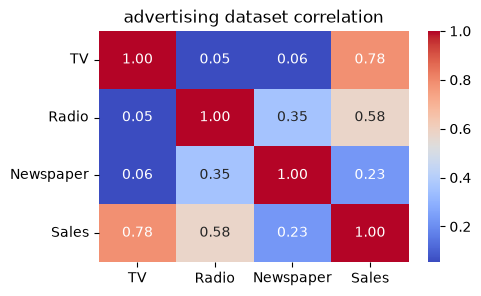

In [88]:
plt.figure(figsize=(5, 3))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("advertising dataset correlation")
plt.show()

### Observation
Tv has strongest coorelation with sales as it is 0.78 followed by radio and then newspaper. It means that TV and radio shows bigger relationship with sales by advertising them.


#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [22]:

from sklearn.preprocessing import StandardScaler


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=17)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape, X_test_scaled.shape)

(134, 3) (66, 3)


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [ ]:
linear_regression = LinearRegression()
linear_regression.fit(X_train_scaled, y_train)
print ("Intercept:", linear_regression.intercept_) #b0
print ("Coefficients:", linear_regression.coef_) #b1

Intercept: 14.022388059701495
Coefficients: [ 3.9675339   2.88155345 -0.07344038]


In [25]:
y_pred = linear_regression.predict(X_test_scaled)
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
comparison.head()

,Actual,Predicted
0,22.1,20.488582
1,13.2,15.296503
2,7.3,10.552781
3,20.2,20.025001
4,12.8,12.843469


# 
Most actual sales points are quite closer to the predicted ones which shows that the model seems to fit the data quite well

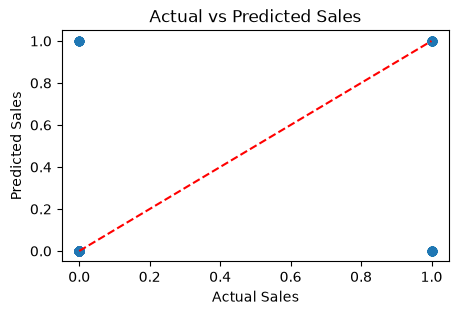

In [87]:
plt.figure(figsize=(5, 3))
plt.scatter(y_test, y_pred,alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')  # Line for perfect prediction
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

#### 2.5 Evaluate created model with above functions

In [28]:
print("MAE:", MAE(y_test, y_pred))
print("MSE:", MSE(y_test, y_pred))
print("SSE:", SSE(y_test, y_pred))
print("RMSE:", RMSE(y_test, y_pred))
print("MAPE:", MAPE(y_test, y_pred))
print ("R2:", R2(y_test, y_pred))


MAE: 1.241490259650847
MSE: 3.4726299687527886
SSE: 229.19357793768404
RMSE: 1.8634993879131778
MAPE: 18.638804594568974
R2: 0.8515370160992793


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [33]:

from sklearn.model_selection import cross_val_score


cv_score = cross_val_score(linear_regression, X_train_scaled, y_train, cv=10, scoring='r2')

print('r2_score', cv_score)
print('Mean r2_score:', cv_score.mean())

r2_score [0.95167662 0.86776129 0.92327432 0.85257085 0.9089784  0.86938345
 0.91258865 0.81872442 0.92976358 0.94797723]
Mean r2_score: 0.8982698791408206


#
average R2 score fromm cross validation is sitting around approximately ~0.90 which proves the model is performing good towards different part of training Data

#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [34]:
X_reduced= advertising[["TV", "Radio"]]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reduced, y, test_size=0.33, random_state=17)
reduced_scaler = StandardScaler()
Xr_train_scaled = reduced_scaler.fit_transform(Xr_train)
Xr_test_scaled = reduced_scaler.transform(Xr_test)

reduced_model= LinearRegression()
reduced_model.fit(Xr_train_scaled, yr_train)
reduced_y_pred = reduced_model.predict(Xr_test_scaled)

In [35]:
print ("full MSE MODEL:", MSE(y_test, y_pred))
print ("reduced MSE MODEL:", MSE(yr_test, reduced_y_pred))
print ("full R2 MODEL:", R2(y_test, y_pred))
print ("reduced R2 MODEL:", R2(yr_test, reduced_y_pred))

full MSE MODEL: 3.4726299687527886
reduced MSE MODEL: 3.4587409987632234
full R2 MODEL: 0.8515370160992793
reduced R2 MODEL: 0.8521308017736854


### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [42]:
lasso_model = Lasso(alpha=1)
lasso_model.fit(X_train_scaled, y_train)
lasso_pred = lasso_model.predict(X_test_scaled)
print("Lasso MSE:", mean_squared_error(y_test, lasso_pred))
print("Lasso cooefficients:", lasso_model.coef_)


Lasso MSE: 4.911579294712751
Lasso cooefficients: [3.0619592  1.96202634 0.        ]


#### 3.2 Ridge regression

In [89]:
ridge_model = Ridge(alpha=1)
ridge_model.fit(X_train_scaled, y_train)
ridge_pred = ridge_model.predict(X_test_scaled)
print("Ridge MSE:", mean_squared_error(y_test, ridge_pred))
print ("Ridge cooefficients:", ridge_model.coef_)


Ridge MSE: 0.15822995337324133
Ridge cooefficients: [ 0.07049025  0.20156216 -0.01141209 -0.00707819 -0.01451491  0.08946253
  0.04529564  0.03511259]


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [47]:
elastic_model = ElasticNet(alpha=1, l1_ratio=0.5)
elastic_model.fit(X_train_scaled, y_train)
elastic_pred = elastic_model.predict(X_test_scaled)
print("Elastic Net MSE:", mean_squared_error(y_test, elastic_pred))
print("Elastic Net coefficients:", elastic_model.coef_)

Elastic Net MSE: 6.843883320104107
Elastic Net coefficients: [2.39397459 1.68907463 0.01489489]


#### 3.4 Make conclusions

#
Elastic net regression gave the highest mean squared error which is 6.84 followed by lasso 4.91 then ridge regression MSE ~3.48 which is quite closer to linear regression MSE 3.47 but still overall by all this metrics it has been observed that regularisation in fact did not improve the predictions results and by the cooefficient value zero of newspaper in lasso regression I hve also noticed that this feature was less usefull in regularised model. Overall comparing the results and sales it proves that the Tv and radio has more impact on sales by advertisement than newspaper/

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [52]:
def accuracy(y_true, y_pred):
    return accuracy_score(y_true, y_pred)

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [53]:
def precision(y_true, y_pred):
    return precision_score(y_true, y_pred, zero_division=0)

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [54]:
def recall(y_true, y_pred):
    return recall_score(y_true, y_pred, zero_division=0)

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [71]:
def f1_score(y_true, y_pred):
    return f1(y_true, y_pred)

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [58]:
diabetes = pd.read_csv("diabetes.csv")
columns_to_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for column in columns_to_fix:
    diabetes[column] = diabetes[column].replace(0, diabetes[column].mean())

diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.000000,79.799479,33.6,0.627,50,1
1,1,85.0,66.0,29.000000,79.799479,26.6,0.351,31,0
2,8,183.0,64.0,20.536458,79.799479,23.3,0.672,32,1
3,1,89.0,66.0,23.000000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.000000,168.000000,43.1,2.288,33,1


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [59]:
diabetes.corr(numeric_only=True)[['Outcome']].sort_values(by='Outcome', ascending=False)

,Outcome
Outcome,1.000000
Glucose,0.492908
BMI,0.312254
Age,0.238356
Pregnancies,0.221898
Insulin,0.179185
SkinThickness,0.175026
DiabetesPedigreeFunction,0.173844
BloodPressure,0.162986


### Observation
I have observed that the Glucose has stronger relationship with diabetes Outcome 0.49 which follows by BMI , age and pregnancies. Other features have weaker coorelation.

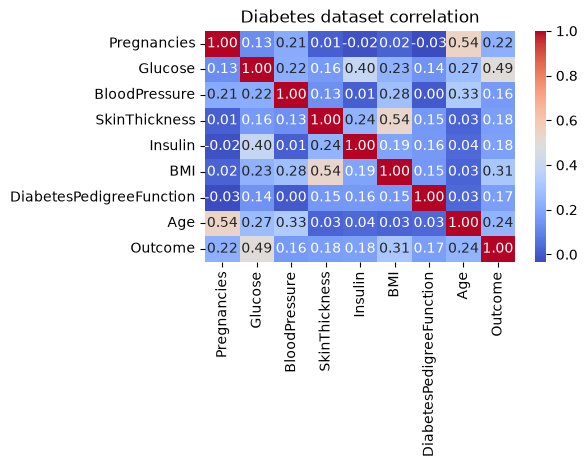

In [61]:
plt.figure(figsize=(5, 3))
sns.heatmap(diabetes.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Diabetes dataset correlation")
plt.show()

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [62]:
X= diabetes.drop(columns=["Outcome"])
y= diabetes["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=17)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print (X_train_scaled.shape, X_test_scaled.shape)

(514, 8) (254, 8)


#### 2.4 Fit logistic regression model, generate predictions

In [63]:
logistic_regression = LogisticRegression()
logistic_regression.fit(X_train_scaled, y_train)
y_pred = logistic_regression.predict(X_test_scaled)
y_prob = logistic_regression.predict_proba(X_test_scaled)[:, 1]
y_pred[:10]

array([0, 1, 0, 0, 0, 0, 0, 1, 1, 1])

#### 2.5 Create a confusion matrix and evaluate created model with above functions

In [72]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

print("Accuracy:", accuracy(y_test, y_pred))
print("Precision:", precision(y_test, y_pred))
print("Recall:", recall(y_test, y_pred))
print("F1_Score:", f1(y_test, y_pred))

Confusion Matrix:
 [[146  19]
 [ 41  48]]
Accuracy: 0.7637795275590551
Precision: 0.7164179104477612
Recall: 0.5393258426966292
F1_Score: 0.6153846153846154


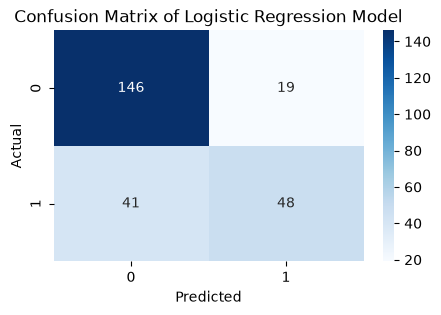

In [73]:
plt.figure(figsize=(5, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix of Logistic Regression Model")
plt.show()

### Observation
recall suggests here that around 54% OF the actual diabetes positive cases detected by the model also 146 cases are predicted as negative cases which are correct. 41 false negatives and 19 false positives. 48 cases correctly predicted diabetes

#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

AUC: 0.8332311882873681


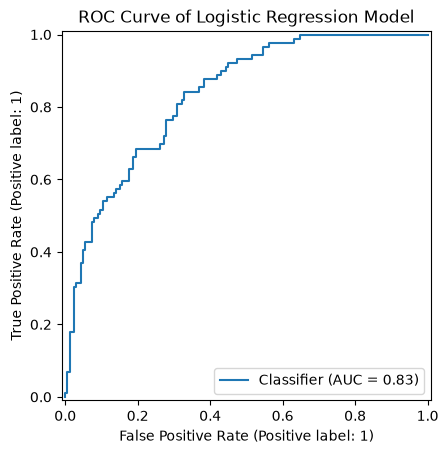

In [76]:
print("AUC:", roc_auc_score(y_test, y_prob))
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve of Logistic Regression Model")
plt.show()

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [78]:
log_cv= cross_val_score(LogisticRegression(), X_train_scaled, y_train, cv=10, scoring='accuracy')
print("Cross-validated accuracy scores:", log_cv)
print("Mean cross-validated accuracy:", log_cv.mean())

Cross-validated accuracy scores: [0.67307692 0.82692308 0.78846154 0.75       0.70588235 0.76470588
 0.88235294 0.74509804 0.74509804 0.80392157]
Mean cross-validated accuracy: 0.768552036199095


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [80]:
tree_model = DecisionTreeClassifier(random_state=17)
tree_model.fit(X_train_scaled, y_train)
y_pred_tree = tree_model.predict(X_test_scaled)
y_prob_tree = tree_model.predict_proba(X_test_scaled)[:, 1]
y_pred_tree[:10]

array([0, 1, 0, 0, 0, 1, 0, 1, 1, 1])

#### 3.2 Evaluate created model with above functions

In [81]:
cm_tree= confusion_matrix(y_test, y_pred_tree)
print("Confusion Matrix for Decision Tree:\n", cm_tree)

print("Accuracy for Decision Tree:", accuracy(y_test, y_pred_tree))
print("Precision for Decision Tree:", precision(y_test, y_pred_tree))
print("Recall for Decision Tree:", recall(y_test, y_pred_tree))
print("F1_Score for Decision Tree:", f1(y_test, y_pred_tree))

Confusion Matrix for Decision Tree:
 [[128  37]
 [ 26  63]]
Accuracy for Decision Tree: 0.7519685039370079
Precision for Decision Tree: 0.63
Recall for Decision Tree: 0.7078651685393258
F1_Score for Decision Tree: 0.6666666666666666


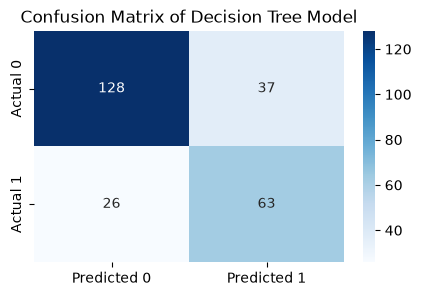

In [83]:
plt.figure(figsize=(5, 3))
sns.heatmap(cm_tree, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'])

plt.title("Confusion Matrix of Decision Tree Model")
plt.show()

#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

AUC:  0.7418113721484507


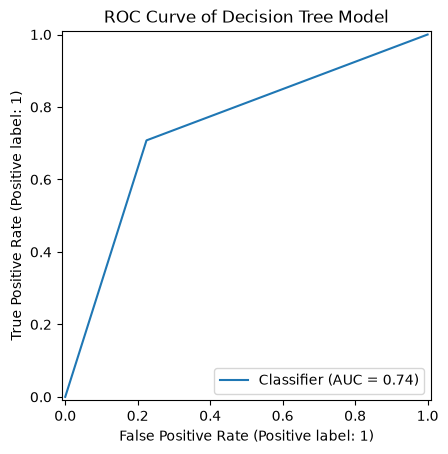

In [84]:
print("AUC: ", roc_auc_score(y_test, y_prob_tree))
RocCurveDisplay.from_predictions(y_test, y_prob_tree)
plt.title("ROC Curve of Decision Tree Model")
plt.show()

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [85]:
tree_cv= cross_val_score(DecisionTreeClassifier(random_state=17), X_train_scaled, y_train, cv=10, scoring='accuracy')
print("Accuracy Scores for Decision Tree:", tree_cv)
print("Mean Accuracy for Decision Tree:", tree_cv.mean())

Accuracy Scores for Decision Tree: [0.61538462 0.73076923 0.69230769 0.71153846 0.64705882 0.66666667
 0.88235294 0.68627451 0.68627451 0.76470588]
Mean Accuracy for Decision Tree: 0.7083333333333334


#### 3.5 Make conclusions

### Conclusion
After looking at the confusion matrix of decision tree it shown that this model correctly predicted 128 diabetes negative casses and 63 positive cases which is actually better detection of cases than logistic regression model and also has better recall 71% but decision tree also produced more false positves 37. Auc score of decision tree is 0.74 which is lower than logistic regression, What it means ? it means that logistic regression model performs bwtter at distinguishing between the two clases overall. Logistic regression achieved better accuracy 76.4 and Auc(0.83) while decision tree had better recall and f1 score. Interesting part is recall is also important here because missing actual diabetes cases can be fatal. But overall logistic regression worked better according tothe metrics.
